# Graduate Career Opportunity Recommender

## Week 1 - Research foundation

The project examines transparent matching between graduate-student attributes and career opportunities. The current question is whether adding academic-field and preference compatibility to skill coverage improves the ordering of opportunities in fixed synthetic scenarios.

The working hypothesis is that additional attributes may resolve some skill-only ties, but improvement is not assumed for every profile. The opening proposal page, supplied bibliography and selected Jobindex paper establish the topic. The detailed scoring rule below is an initial implementation choice, not a reproduction of the selected paper.

The source inputs are fictional graduate profiles and opportunities. Evidence consists of validated inputs and, in Week 2, computed rankings evaluated against scenario grades. Nothing here establishes employment eligibility, current vacancy availability, placement success or real student utility.

Install `src/requirements.txt` in the notebook kernel environment and open this notebook from the repository root or src folder. Week 1 and Week 2 are milestone sections prepared during the same current work session; they do not represent backdated development activity.


In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd().resolve()
if ROOT.name == "src": ROOT = ROOT.parent
assert (ROOT / "src/protocol.json").exists(), "Open from the project root or src folder"
if str(ROOT / "src") not in sys.path: sys.path.insert(0, str(ROOT / "src"))
print("Project root:", ROOT)
print("Protocol:", json.loads((ROOT/"src/protocol.json").read_text())["research_question"])


Project root: /workspace/scratch/a51446536e17/mohammed_maintenance
Protocol: For fixed synthetic graduate-student scenarios, does a structured score combining skill coverage, academic-field compatibility and stated career preferences improve Precision@3 and NDCG@3 over skill-only ranking?


### Create representative inputs and freeze the rubric

Six profiles cover data science, computer science, business analytics, cybersecurity, health informatics and finance. Twelve fictional opportunities contain canonical required skills, accepted academic fields, opportunity type and work mode. Every profile is evaluated against all opportunities, yielding 72 pairs.

Pair grades are explicitly assigned before any ranker executes. Grade 2 describes a strong intended role fit; grade 1 indicates partial or transferable fit or a material preference limitation; grade 0 indicates no useful match in the scenario. Each pair includes a rationale. These author-defined judgments are conceptually related to the scoring attributes and are not independent labels.

The next cell includes the complete synthetic-input construction. Re-running it deterministically recreates the same input bytes; the experiment verifies their hashes before evaluation.


In [2]:
"""Create small, fixed synthetic scenarios without consulting ranker outputs."""
from pathlib import Path
import json,hashlib
# ROOT is established above
D=ROOT/'data/synthetic'
def generate():
    D.mkdir(parents=True,exist_ok=True)
    profiles=[
    {'student_id':'S01','field':'data_science','skills':['python','sql','statistics','tableau'],'preferred_type':'full_time','preferred_modes':['remote','hybrid']},
    {'student_id':'S02','field':'computer_science','skills':['python','java','git','sql'],'preferred_type':'internship','preferred_modes':['remote']},
    {'student_id':'S03','field':'business_analytics','skills':['sql','excel','powerbi','python'],'preferred_type':'full_time','preferred_modes':['onsite','hybrid']},
    {'student_id':'S04','field':'cybersecurity','skills':['networking','linux','python','security'],'preferred_type':'internship','preferred_modes':['hybrid','remote']},
    {'student_id':'S05','field':'health_informatics','skills':['sql','excel','healthcare','python'],'preferred_type':'full_time','preferred_modes':['remote','hybrid']},
    {'student_id':'S06','field':'finance','skills':['excel','statistics','sql','python'],'preferred_type':'internship','preferred_modes':['remote']}]
    raw=[
    ('O01','Data analyst',['sql','tableau'],['data_science','business_analytics'],'full_time','hybrid'),
    ('O02','Data science intern',['python','statistics'],['data_science','computer_science'],'internship','onsite'),
    ('O03','Backend developer',['python','git'],['computer_science'],'full_time','onsite'),
    ('O04','Software engineering intern',['java','git'],['computer_science'],'internship','remote'),
    ('O05','Business analyst',['excel','requirements'],['business_analytics','computer_science'],'full_time','hybrid'),
    ('O06','Reporting analyst',['sql','powerbi'],['business_analytics','data_science'],'full_time','onsite'),
    ('O07','Security analyst',['linux','security'],['cybersecurity'],'full_time','onsite'),
    ('O08','Security intern',['networking','security'],['cybersecurity'],'internship','hybrid'),
    ('O09','Clinical data analyst',['sql','healthcare'],['health_informatics','data_science'],'full_time','hybrid'),
    ('O10','Health data intern',['excel','healthcare'],['health_informatics'],'internship','onsite'),
    ('O11','Risk analyst',['statistics','excel'],['finance','business_analytics'],'full_time','onsite'),
    ('O12','Finance intern',['excel','sql'],['finance'],'internship','remote')]
    opportunities=[dict(zip(['opportunity_id','title','required_skills','accepted_fields','type','mode'],r)) for r in raw]
    # Pairwise grades are specified before any scoring function is called.
    grades={
    'S01':[2,1,0,0,0,1,0,0,1,0,1,0],
    'S02':[1,0,1,2,0,0,0,0,0,0,0,0],
    'S03':[1,0,0,0,1,2,0,0,0,0,1,1],
    'S04':[0,0,1,0,0,0,1,2,0,0,0,0],
    'S05':[1,0,0,0,1,1,0,0,2,1,0,0],
    'S06':[0,1,0,0,1,1,0,0,0,0,1,2]}
    explanations={
    'S01':{'O01':'Direct analyst role with SQL/Tableau and preferred full-time hybrid context','O02':'Strong technical overlap but internship/onsite conflicts with stated preferences','O06':'Transferable SQL/data background, missing Power BI','O09':'Transferable SQL but no healthcare skill','O11':'Statistics transfers, but Excel and finance context are limited'},
    'S02':{'O01':'Partial SQL fit, missing Tableau and intended analyst specialization','O03':'Direct software skill fit but full-time onsite conflicts with preferences','O04':'Direct Java/Git fit and preferred remote internship'},
    'S03':{'O01':'Transferable SQL/analytics fit, missing Tableau','O05':'Relevant field and Excel, missing requirements skill','O06':'Direct SQL/Power BI and preferred full-time onsite role','O11':'Partial Excel and business fit, missing statistics','O12':'Useful reporting skills, but finance specialization and internship differ from target'},
    'S04':{'O03':'Python is transferable but Git and general software role remain gaps','O07':'Direct security skills but full-time onsite conflicts with internship preference','O08':'Direct networking/security and preferred hybrid internship'},
    'S05':{'O01':'Transferable SQL, missing Tableau','O05':'Excel is useful but requirements skill is absent','O06':'SQL reporting transfers but Power BI is absent','O09':'Direct healthcare/SQL and preferred full-time hybrid context','O10':'Domain and tools align but internship/onsite differ from preferences'},
    'S06':{'O02':'Python/statistics transfer but data-science context and onsite mode are limitations','O05':'Excel transfers but business requirements skill is absent','O06':'SQL reporting transfers but Power BI is absent','O11':'Direct quantitative tools and finance field but full-time onsite differs from preference','O12':'Direct Excel/SQL and preferred remote finance internship'}}
    labels=[{'student_id':sid,'opportunity_id':o['opportunity_id'],'grade':g,'rationale':explanations[sid].get(o['opportunity_id'],'No useful role/domain fit in this constructed scenario')} for sid,gs in grades.items() for o,g in zip(opportunities,gs)]
    for name,data in [('profiles.json',profiles),('opportunities.json',opportunities),('relevance.json',labels)]:
        (D/name).write_text(json.dumps(data,indent=2)+'\n')
    manifest={'provenance':'Manually authored fictional diagnostic cases; no real people or real vacancies. Grades are fixed before scoring and are not independently annotated.','sha256':{p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(D.glob('*.json')) if p.name!='manifest.json'}}
    (D/'manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
    return profiles,opportunities,labels
profiles, opportunities, labels = generate()
print('Prepared', len(profiles), 'profiles,', len(opportunities), 'opportunities and', len(labels), 'graded pairs.')


Prepared 6 profiles, 12 opportunities and 72 graded pairs.


### Validate and summarize inputs

The foundation checks identifier uniqueness, complete pair coverage, reference consistency, grades, required fields, rationales and input digests. It saves descriptive profile/opportunity tables and the label distribution. This milestone does not run the comparative ranking experiment.


In [3]:
"""Inspectable structured matching; labels never enter the scoring functions."""

import math


def normalize(values):
    """Trim, lowercase and deduplicate skill or field names."""
    return {
        value.strip().lower()
        for value in values
        if isinstance(value, str) and value.strip()
    }


def components(profile, opportunity):
    """Calculate the existing skill, field and preference match components."""
    required_skills = normalize(opportunity["required_skills"])
    if not required_skills:
        raise ValueError("At least one required skill is needed")

    skill_coverage = len(normalize(profile["skills"]) & required_skills) / len(
        required_skills
    )
    field_match = float(
        profile["field"].strip().lower() in normalize(opportunity["accepted_fields"])
    )
    type_match = float(profile["preferred_type"] == opportunity["type"])
    mode_match = float(opportunity["mode"] in profile["preferred_modes"])
    return {
        "skill_coverage": skill_coverage,
        "field_match": field_match,
        "type_match": type_match,
        "mode_match": mode_match,
        "preference_match": (type_match + mode_match) / 2,
    }


def structured_score(parts, protocol):
    """Combine the three components using the predeclared weights."""
    weights = [
        protocol[key] for key in ["skill_weight", "field_weight", "preference_weight"]
    ]
    if any(weight < 0 for weight in weights) or not math.isclose(sum(weights), 1):
        raise ValueError("Weights must be nonnegative and sum to one")
    return (
        weights[0] * parts["skill_coverage"]
        + weights[1] * parts["field_match"]
        + weights[2] * parts["preference_match"]
    )


def ordered(rows, score):
    """Sort by descending score, resolving ties by opportunity ID."""
    return sorted(rows, key=lambda row: (-row[score], row["opportunity_id"]))


def precision_at_k(grades, k):
    """Measure the relevant fraction of the first k graded candidates."""
    if k < 1 or len(grades) < k:
        raise ValueError("Invalid k")
    return sum(grade >= 1 for grade in grades[:k]) / k


def ndcg_at_k(grades, k):
    """Normalize discounted exponential gains against the ideal ordering."""
    if k < 1 or len(grades) < k:
        raise ValueError("Invalid k")

    def discounted_gain(ordered_grades):
        return sum(
            (2**grade - 1) / math.log2(index + 2)
            for index, grade in enumerate(ordered_grades[:k])
        )

    ideal_gain = discounted_gain(sorted(grades, reverse=True))
    return discounted_gain(grades) / ideal_gain if ideal_gain else 0.0


def _require_records(records, name):
    """Reject empty collections and non-object rows before indexing fields."""
    if not isinstance(records, list) or not records:
        raise ValueError(f"{name} must be a nonempty list of objects")
    for index, record in enumerate(records):
        if not isinstance(record, dict):
            raise ValueError(f"{name}[{index}] must be an object")


def _require_text(record, field, location):
    value = record.get(field)
    if not isinstance(value, str) or not value.strip():
        raise ValueError(f"{location}.{field} must be a nonempty string")


def _require_text_list(record, field, location, allow_empty=False):
    """Validate list types without silently dropping malformed entries."""
    values = record.get(field)
    if not isinstance(values, list) or (not allow_empty and not values):
        qualifier = "a list" if allow_empty else "a nonempty list"
        raise ValueError(f"{location}.{field} must be {qualifier} of nonempty strings")
    if any(not isinstance(value, str) or not value.strip() for value in values):
        raise ValueError(f"{location}.{field} must contain only nonempty strings")


def validate_inputs(profiles, opportunities, labels):
    """Validate schema first, then identifier, pair-grid and relevance integrity.

    Empty profile skill lists are valid. Required opportunity skills, accepted
    fields and preferred work modes must be nonempty lists. Successful calls
    retain the original check names so existing evidence tables stay comparable.
    """
    for records, name in [
        (profiles, "profiles"),
        (opportunities, "opportunities"),
        (labels, "labels"),
    ]:
        _require_records(records, name)

    for index, profile in enumerate(profiles):
        location = f"profiles[{index}]"
        for field in ["student_id", "field", "preferred_type"]:
            _require_text(profile, field, location)
        _require_text_list(profile, "skills", location, allow_empty=True)
        _require_text_list(profile, "preferred_modes", location)

    for index, opportunity in enumerate(opportunities):
        location = f"opportunities[{index}]"
        for field in ["opportunity_id", "title", "type", "mode"]:
            _require_text(opportunity, field, location)
        _require_text_list(opportunity, "required_skills", location)
        _require_text_list(opportunity, "accepted_fields", location)

    for index, label in enumerate(labels):
        location = f"labels[{index}]"
        for field in ["student_id", "opportunity_id", "rationale"]:
            _require_text(label, field, location)

    student_ids = {profile["student_id"] for profile in profiles}
    opportunity_ids = {opportunity["opportunity_id"] for opportunity in opportunities}
    labeled_pairs = [(label["student_id"], label["opportunity_id"]) for label in labels]
    expected_pairs = {
        (student_id, opportunity_id)
        for student_id in student_ids
        for opportunity_id in opportunity_ids
    }
    checks = {
        "unique_student_ids": len(student_ids) == len(profiles),
        "unique_opportunity_ids": len(opportunity_ids) == len(opportunities),
        "unique_labeled_pairs": len(set(labeled_pairs)) == len(labeled_pairs),
        "complete_pair_grid": set(labeled_pairs) == expected_pairs,
        "valid_relevance_grades": all(
            type(label.get("grade")) is int and label["grade"] in {0, 1, 2}
            for label in labels
        ),
        "required_profile_fields": True,
        "required_opportunity_fields": True,
        "pair_rationales_present": True,
    }
    failed_checks = [name for name, passed in checks.items() if not passed]
    if failed_checks:
        raise ValueError("Input integrity checks failed: " + ", ".join(failed_checks))
    return checks


In [4]:
"""Week 1: input validation and descriptive evidence, without comparative results."""

from pathlib import Path
import json
import hashlib
import platform
import importlib.metadata
import pandas as pd


def run():
    """Validate the fixed inputs and save the Week 1 descriptive evidence."""
    input_dir = ROOT / "data/synthetic"
    output_dir = ROOT / "results/week_1"
    output_dir.mkdir(parents=True, exist_ok=True)
    profiles = json.loads((input_dir / "profiles.json").read_text())
    opportunities = json.loads((input_dir / "opportunities.json").read_text())
    labels = json.loads((input_dir / "relevance.json").read_text())
    manifest = json.loads((input_dir / "manifest.json").read_text())
    for filename, expected_hash in manifest["sha256"].items():
        if (
            hashlib.sha256((input_dir / filename).read_bytes()).hexdigest()
            != expected_hash
        ):
            raise ValueError("Frozen input changed: " + filename)
    checks = validate_inputs(profiles, opportunities, labels)
    checks["input_digests_match"] = True
    pd.DataFrame(
        [{"check": name, "passed": passed} for name, passed in checks.items()]
    ).to_csv(output_dir / "validation_checks.csv", index=False)
    pd.DataFrame(
        [
            {
                "student_id": profile["student_id"],
                "field": profile["field"],
                "skills": len(profile["skills"]),
                "preferred_type": profile["preferred_type"],
                "preferred_modes": "|".join(profile["preferred_modes"]),
            }
            for profile in profiles
        ]
    ).to_csv(output_dir / "profile_summary.csv", index=False)
    pd.DataFrame(
        [
            {
                "opportunity_id": opportunity["opportunity_id"],
                "title": opportunity["title"],
                "required_skills": "|".join(opportunity["required_skills"]),
                "accepted_fields": "|".join(opportunity["accepted_fields"]),
                "type": opportunity["type"],
                "mode": opportunity["mode"],
            }
            for opportunity in opportunities
        ]
    ).to_csv(output_dir / "opportunity_summary.csv", index=False)
    pd.DataFrame(labels).groupby(["student_id", "grade"]).size().unstack(
        fill_value=0
    ).to_csv(output_dir / "grade_distribution.csv")
    summary = {
        "profiles": len(profiles),
        "opportunities": len(opportunities),
        "pairs": len(labels),
        "fields": len({profile["field"] for profile in profiles}),
        "checks_passed": len(checks),
        "comparative_experiment_executed": False,
        "python": platform.python_version(),
        "packages": {
            package: importlib.metadata.version(package)
            for package in ["numpy", "pandas"]
        },
        "input_hashes": manifest["sha256"],
    }
    (output_dir / "execution_summary.json").write_text(
        json.dumps(summary, indent=2) + "\n"
    )
    print(json.dumps(summary, indent=2))
    return summary


foundation_summary = run()


{
  "profiles": 6,
  "opportunities": 12,
  "pairs": 72,
  "fields": 6,
  "checks_passed": 9,
  "comparative_experiment_executed": false,
  "python": "3.12.14",
  "packages": {
    "numpy": "2.3.5",
    "pandas": "2.2.3"
  },
  "input_hashes": {
    "opportunities.json": "e41fee5972bd077f221f8ba044487336e60522b324036e43473ebf099bb6850c",
    "profiles.json": "8cdc6ce1665751bef3a80fee821ffa92e4fe5790b8f8a07ae94b5eebdcf597dd",
    "relevance.json": "8113372ac72b8acac51246ecd5587549c150312d96049a9496b77661f43a96d2"
  }
}


### Week 1 observations and next step

The generated inputs contain six complete profiles, twelve opportunities and all 72 graded pairs. All nine foundation checks passed. These outputs demonstrate that the intended research inputs can be created, validated and summarized reproducibly. They do not yet compare ranking quality.

The main early limitation is the absence of independent relevance judgments or interaction data. A small synthetic collection is suitable for checking the workflow, but cannot establish usefulness for actual graduate students. The Week 2 implementation below adds a fixed structured score, a skill-only reference, known-example tests and an initial controlled comparison without tuning the weights to the resulting metrics.


## Week 2 - Structured method and initial comparison

Both methods rank the same twelve opportunities for each profile. Skill-only scoring measures the fraction of an opportunity's required skills present in the profile. The proposed score is `0.60 * skill_coverage + 0.25 * field_match + 0.15 * preference_match`.

Academic-field compatibility is 1 if the profile field appears in the opportunity's accepted-field list, otherwise 0. Preference compatibility averages two binary checks: opportunity type and work mode. Ties use opportunity ID in ascending order. No embedding model, classifier, collaborative signal or training process is involved.

Weights, grades, candidates and K=3 are fixed before scoring. Precision@3 treats grades 1 and 2 as relevant. NDCG@3 uses gain `2**grade-1` and discount `log2(rank+1)`, normalized by the ideal ordering of the same twelve candidates. Both metrics are calculated for each scenario and then macro-averaged across six profiles.


In [5]:
import unittest, io
suite = unittest.defaultTestLoader.discover(str(ROOT / "src"), pattern="test_*.py")
test_log = io.StringIO()
result = unittest.TextTestRunner(stream=test_log, verbosity=2).run(suite)
print(test_log.getvalue())
assert result.wasSuccessful(), "Resolve test failures before interpreting evidence"
(ROOT / "results/week_2").mkdir(parents=True, exist_ok=True)
(ROOT / "results/week_2/method_tests.txt").write_text(test_log.getvalue())


test_bad_weights_rejected (test_career_methods.MethodTests.test_bad_weights_rejected) ... ok
test_empty_required_rejected (test_career_methods.MethodTests.test_empty_required_rejected) ... ok
test_invalid_k (test_career_methods.MethodTests.test_invalid_k) ... ok
test_label_grid_rejected (test_career_methods.MethodTests.test_label_grid_rejected) ... ok
test_ndcg_hand_calculation (test_career_methods.MethodTests.test_ndcg_hand_calculation) ... ok
test_ndcg_perfect (test_career_methods.MethodTests.test_ndcg_perfect) ... ok
test_ndcg_zero (test_career_methods.MethodTests.test_ndcg_zero) ... ok
test_no_skills (test_career_methods.MethodTests.test_no_skills) ... ok
test_normalization (test_career_methods.MethodTests.test_normalization) ... ok
test_partial_coverage (test_career_methods.MethodTests.test_partial_coverage) ... ok
test_precision_known (test_career_methods.MethodTests.test_precision_known) ... ok
test_preferences_half (test_career_methods.MethodTests.test_preferences_half) ... ok


### Execute the fixed comparison

The following code computes component scores without receiving relevance labels. Labels are joined only after ranking for evaluation. Complete rankings, component values, metric tables and per-profile differences are saved to `results/week_2/`.

This is an initial diagnostic benchmark. There is no supervised training/test split, learned parameter or weight selection, and the scenarios should not be described as an independent held-out evaluation.


    method  precision_at_3  ndcg_at_3
skill_only        0.833333   0.839573
structured        0.833333   0.939481

Per-scenario differences:
            precision_at_3_skill_only  precision_at_3_structured  ndcg_at_3_skill_only  ndcg_at_3_structured  precision_at_3_delta  ndcg_at_3_delta
student_id                                                                                                                                         
S01                          0.666667                   1.000000              0.878962              1.000000              0.333333         0.121038
S02                          1.000000                   0.666667              0.821314              0.878962             -0.333333         0.057648
S03                          1.000000                   1.000000              1.000000              1.000000              0.000000         0.000000
S04                          0.666667                   0.666667              0.700276              0.878962           

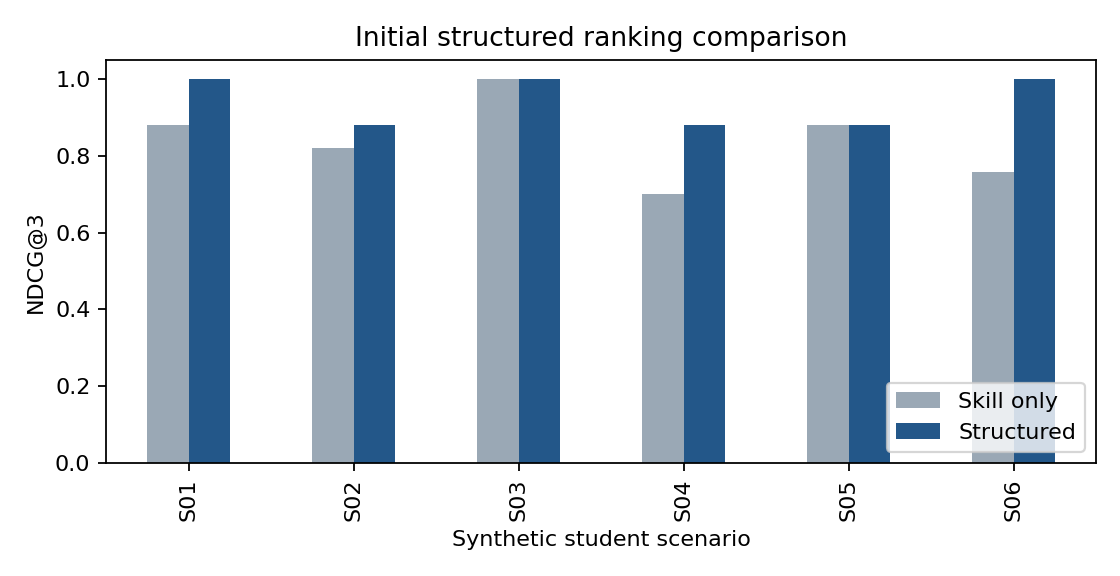

In [6]:
"""Week 2: compare fixed structured scoring with a skill-only reference."""

from pathlib import Path
import json
import hashlib
import platform
import importlib.metadata
import math
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt


def run():
    """Run both fixed rankers and save the Week 2 comparison evidence."""
    input_dir = ROOT / "data/synthetic"
    output_dir = ROOT / "results/week_2"
    output_dir.mkdir(parents=True, exist_ok=True)
    protocol_bytes = (ROOT / "src/protocol.json").read_bytes()
    protocol = json.loads(protocol_bytes)
    profiles = json.loads((input_dir / "profiles.json").read_text())
    opportunities = json.loads((input_dir / "opportunities.json").read_text())
    labels = json.loads((input_dir / "relevance.json").read_text())
    manifest = json.loads((input_dir / "manifest.json").read_text())
    for name, expected_hash in manifest["sha256"].items():
        if hashlib.sha256((input_dir / name).read_bytes()).hexdigest() != expected_hash:
            raise ValueError("Frozen input changed: " + name)
    checks = validate_inputs(profiles, opportunities, labels)
    checks["input_digests_match"] = True
    grades = {
        (label["student_id"], label["opportunity_id"]): label["grade"]
        for label in labels
    }
    scores = []
    ranks = []
    metric_rows = []
    for profile in profiles:
        candidates = []
        for opportunity in opportunities:
            parts = components(profile, opportunity)
            candidates.append(
                {
                    "student_id": profile["student_id"],
                    "opportunity_id": opportunity["opportunity_id"],
                    **parts,
                    "skill_only": parts["skill_coverage"],
                    "structured": structured_score(parts, protocol),
                }
            )
        scores.extend(candidates)
        for method in ["skill_only", "structured"]:
            ranked = ordered(candidates, method)
            ranked_grades = [
                grades[profile["student_id"], candidate["opportunity_id"]]
                for candidate in ranked
            ]
            for rank, candidate in enumerate(ranked, 1):
                ranks.append(
                    {
                        "student_id": profile["student_id"],
                        "method": method,
                        "opportunity_id": candidate["opportunity_id"],
                        "rank": rank,
                        "score": candidate[method],
                        "grade": ranked_grades[rank - 1],
                    }
                )
            metric_rows.append(
                {
                    "student_id": profile["student_id"],
                    "method": method,
                    "precision_at_3": precision_at_k(ranked_grades, protocol["k"]),
                    "ndcg_at_3": ndcg_at_k(ranked_grades, protocol["k"]),
                }
            )
    score_table = pd.DataFrame(scores)
    ranking_table = pd.DataFrame(ranks)
    metrics = pd.DataFrame(metric_rows)
    aggregate = (
        metrics.groupby("method")[["precision_at_3", "ndcg_at_3"]].mean().reset_index()
    )
    checks["all_scores_finite_and_bounded"] = bool(
        score_table[["skill_only", "structured"]]
        .map(lambda value: math.isfinite(value) and 0 <= value <= 1)
        .all()
        .all()
    )
    checks["two_full_rankings_per_profile"] = len(ranks) == 2 * len(labels)
    checks["grades_unchanged_during_execution"] = (
        hashlib.sha256((input_dir / "relevance.json").read_bytes()).hexdigest()
        == manifest["sha256"]["relevance.json"]
    )
    checks["protocol_unchanged_during_execution"] = (
        ROOT / "src/protocol.json"
    ).read_bytes() == protocol_bytes
    assert all(checks.values())
    for name, frame in [
        ("score_components", score_table),
        ("rankings", ranking_table),
        ("metrics_by_student", metrics),
        ("metrics_summary", aggregate),
    ]:
        frame.to_csv(output_dir / (name + ".csv"), index=False)
    pd.DataFrame(
        [{"check": name, "passed": passed} for name, passed in checks.items()]
    ).to_csv(output_dir / "validation_checks.csv", index=False)
    ranking_table[ranking_table["rank"] <= 3].to_csv(
        output_dir / "top3_recommendations.csv", index=False
    )
    paired = metrics.pivot(
        index="student_id", columns="method", values=["precision_at_3", "ndcg_at_3"]
    )
    paired.columns = ["_".join(column) for column in paired.columns]
    for metric in ["precision_at_3", "ndcg_at_3"]:
        paired[metric + "_delta"] = (
            paired[metric + "_structured"] - paired[metric + "_skill_only"]
        )
    paired.to_csv(output_dir / "paired_differences.csv")
    figure, axes = plt.subplots(figsize=(7, 3.6))
    ndcg_by_student = metrics.pivot(
        index="student_id", columns="method", values="ndcg_at_3"
    )
    ndcg_by_student.plot.bar(ax=axes, color=["#9AA8B5", "#235789"])
    axes.set_ylim(0, 1.05)
    axes.set(
        ylabel="NDCG@3",
        xlabel="Synthetic student scenario",
        title="Initial structured ranking comparison",
    )
    axes.legend(["Skill only", "Structured"], loc="lower right")
    figure.tight_layout()
    figure.savefig(output_dir / "ndcg_by_student.png", dpi=160)
    plt.close(figure)
    summary = {
        "python": platform.python_version(),
        "packages": {
            package: importlib.metadata.version(package)
            for package in ["numpy", "pandas", "matplotlib"]
        },
        "profiles": len(profiles),
        "opportunities": len(opportunities),
        "pairs": len(labels),
        "protocol": protocol,
        "protocol_sha256": hashlib.sha256(protocol_bytes).hexdigest(),
        "input_hashes": manifest["sha256"],
        "validation_checks_passed": len(checks),
        "training": "none",
        "randomness": "none",
        "independent_annotations": False,
    }
    (output_dir / "execution_summary.json").write_text(
        json.dumps(summary, indent=2) + "\n"
    )
    print(aggregate.to_string(index=False))
    print("\nPer-scenario differences:\n" + paired.to_string())
    return aggregate


comparison_summary = run()


### Initial observations

| Method | Macro Precision@3 | Macro NDCG@3 |
|---|---:|---:|
| Skill only | 0.833333 | 0.839573 |
| Structured score | 0.833333 | 0.939481 |

The combined score improved average NDCG@3 by 0.099908 on these six scenarios, while average Precision@3 stayed unchanged. This indicates better placement of high-grade opportunities within the chosen scenarios rather than an overall increase in the number of relevant top-three recommendations.

The Precision@3 change was mixed: S01 improved from 0.666667 to 1.000000, whereas S02 fell from 1.000000 to 0.666667. The two changes cancel in the macro average. Scenario-level results are retained so the average does not conceal this failure.

For S02, the preferred remote software internship O04 moves above the less-preferred backend role O03, which helps NDCG. However, O02 enters the structured top three despite grade 0, reducing Precision@3. The academic-field list accepts computer science, but the profile lacks statistics and the scenario labels do not consider this a useful target role. This exposes a limitation of broad field compatibility.

S05 still receives finance internship O12 in the top three despite grade 0: Excel/SQL coverage remains strong enough to outweigh the domain and opportunity-type mismatch. A soft compatibility score does not enforce every contextual requirement.

All 28 method tests (14 original tests and 14 input-validation regression tests) and 13 Week 2 input/numerical checks passed. The tests support correct execution of the formulas and validation logic; they do not independently establish that the rubric represents student preferences accurately.

### Interpretation and remaining work

The code now generates traceable recommendations and comparisons relevant to the question. The measured gain is preliminary and does not demonstrate general effectiveness. Because the grade rubric and method use related concepts, favorable results could partly reflect how the scenarios were designed. No labels or weights were changed after observing scores.

Future work should expand the scenarios, obtain independent pair judgments where feasible, separate development scenarios from final evaluation before any tuning, and inspect whether soft compatibility should be replaced by selected hard constraints. More profiles alone do not create independent evidence if they follow the same construction rules. Week 3 investigation and final research conclusions remain pending.

### Evidence and reproduction

The reusable method is in `src/career_methods.py`; `src/run_foundation.py` and `src/run_comparison.py` reproduce the two milestones. Inputs and rationale-bearing labels are under `data/synthetic/`. The manifest records fixed input hashes, and `src/protocol.json` records design choices. The notebook includes actual executed output from the recorded environment.

The selected Kaya and Bogers Jobindex paper concerns candidate recommendations in a recruiter workflow. This project ranks opportunities for student profiles and does not reproduce its deployed algorithm or human-interaction study. The supplied bibliography is retained under `docs/references/`.


# Week 3 - Contribution of recommendation criteria

This analysis compares the skills-only reference, the full structured score, and two variants that remove one criterion at a time. It reuses the existing score components and relevance judgments for six synthetic graduate profiles. The Week 2 settings for the remaining criteria stay fixed in each comparison.

Run the following cell from the repository root or src folder to verify the Week 2 reference rankings and regenerate the three Week 3 result tables.


In [1]:
import runpy
from pathlib import Path

week3_root = Path.cwd().resolve()
if week3_root.name == "src":
    week3_root = week3_root.parent

analysis_path = week3_root / "src/run_week3_evidence.py"
runpy.run_path(str(analysis_path), run_name="__main__")
print((week3_root / "results/week_3/ablation_macro.csv").read_text(encoding="utf-8"))


Checked 72 labeled pairs and reproduced both Week 2 references.
method,profiles,precision_at_3,ndcg_at_3
skill_only,6,0.8333333333333333,0.8395727990663435
structured,6,0.8333333333333333,0.9394809365170496
without_field,6,0.8333333333333333,0.9341984391382507
without_preference,6,0.8333333333333333,0.850137793823941



## Week 3 observations

The full score reached macro NDCG@3 of 0.9395, compared with 0.8396 for skills alone. Removing preferences reduced it to 0.8501, while removing academic field reduced it to 0.9342. Macro Precision@3 was 0.8333 in all four conditions. The preference term produced the larger observed change in ranking quality on these six profiles.

The synthetic grades incorporate contextual fit, so the observed effect may partly reflect the benchmark's design. A broader evaluation should include independently graded profiles and distinguish hard eligibility requirements from soft preferences. See docs/step_2/week_3/preliminary_evidence.pdf for the evidence and next research tasks.
